# Laboratory 2 homework

In [1]:
import duckdb

db = duckdb.connect("data/duckdb_trains_hw.db")
db.sql("SET enable_progress_bar = false")

## 1. Download data

Downloaded in the CLI with:

```bash
bash download_datasets.sh
```

## 2. Put stations data into `stations` table in DuckDB

In [2]:
db.sql("""
CREATE OR REPLACE TABLE stations AS
FROM 'data/stations-2023-09.csv'
""")

## 3. Create tables `distances` and `distances_long`

In [3]:
db.sql("""
CREATE OR REPLACE TABLE distances AS
FROM read_csv('data/tariff-distances-2022-01.csv', nullstr = 'XXX')
""")

db.sql("""
CREATE OR REPLACE TABLE distances_long AS
UNPIVOT distances
ON COLUMNS (* EXCLUDE station)
INTO NAME other_station VALUE distance
""")

## 4. Put train disruptions into `disruptions` table in the Postgres database

In [4]:
db.sql("""INSTALL postgres; LOAD postgres;""")
conn_string = "host=localhost user=postgres password=postgres dbname=postgres"

db.sql(f"""
ATTACH IF NOT EXISTS '{conn_string}' AS postgres_db (TYPE postgres)
""")

db.sql("""
CREATE OR REPLACE TABLE postgres_db.disruptions AS
FROM read_csv(['data/disruptions-201[1-9].csv', 'data/disruptions-202[0-3].csv'])
""")

## 5. Transform train services CSV files into a single Parquet file, make table `services` from it

In [5]:
db.sql("""
COPY (SELECT * FROM 'data/services-20??.csv.gz') TO 'data/services_2019-2025.parquet' (FORMAT PARQUET, COMPRESSION ZSTD)
""")

db.sql("""
CREATE OR REPLACE TABLE services AS
FROM read_parquet('data/services_2019-2025.parquet')
""")

## 7. Questions

### 7.1 How many trains departed from Amsterdam Central station overall?

In [6]:
db.sql("""
FROM services
SELECT COUNT(*) AS total_trains_departed_from_amsterdam_centraal
WHERE "Stop:Station code" = 'ASD' AND "Stop:Departure time" IS NOT NULL
""")

┌───────────────────────────────────────────────┐
│ total_trains_departed_from_amsterdam_centraal │
│                     int64                     │
├───────────────────────────────────────────────┤
│                                       1940873 │
└───────────────────────────────────────────────┘

### 7.2 Calculate the average arrival delay of different service types (`Service:Type`). Order results descending by average delay.

In [7]:
db.sql("""
FROM services
SELECT "Service:Type", AVG("Stop:Arrival delay") AS avg_arrival_delay
GROUP BY ALL
ORDER BY avg_arrival_delay DESC
""").show(max_rows=50)

┌──────────────────────┬────────────────────────┐
│     Service:Type     │   avg_arrival_delay    │
│       varchar        │         double         │
├──────────────────────┼────────────────────────┤
│ Alpen Express        │      31.84254143646409 │
│ Krokus Express       │     18.304347826086957 │
│ European Sleeper     │     14.262589044460821 │
│ Nightjet             │       9.42391097403092 │
│ ICE                  │       7.76692176533566 │
│ Eurostar             │      7.302104678961749 │
│ ICE International    │      5.482790573052148 │
│ Thalys               │     5.3961896909446025 │
│ Int. Trein           │      4.677560708417016 │
│ Nachttrein           │     3.8370501214396113 │
│ Stoomtrein           │      3.366863905325444 │
│ Dinner Train         │      2.633956386292835 │
│ Eurocity Direct      │      2.403207854975682 │
│ Intercity direct     │     2.0744213670832377 │
│ EuroCity             │     1.9711756266988825 │
│ RE 19                │     1.9698529411764707 │


### 7.3 What was the most common disruption cause in different years?

In [8]:
db.sql("""
FROM postgres_db.disruptions
SELECT YEAR(start_time) AS year, MODE(statistical_cause_en) AS most_common_cause
GROUP BY ALL
ORDER BY year
""")

┌───────┬───────────────────┐
│ year  │ most_common_cause │
│ int64 │      varchar      │
├───────┼───────────────────┤
│  2011 │ broken down train │
│  2012 │ points failure    │
│  2013 │ points failure    │
│  2014 │ broken down train │
│  2015 │ broken down train │
│  2016 │ broken down train │
│  2017 │ broken down train │
│  2018 │ broken down train │
│  2019 │ broken down train │
│  2020 │ broken down train │
│  2021 │ broken down train │
│  2022 │ broken down train │
│  2023 │ broken down train │
├───────┴───────────────────┤
│ 13 rows         2 columns │
└───────────────────────────┘

### 7.4 How many trains started their overall service in any Amsterdam station?

In [9]:
db.sql("""
FROM services
SELECT COUNT(DISTINCT "Service:RDT-ID") AS total_trains_started_in_amsterdam
WHERE "Stop:Arrival time" IS NULL AND "Stop:Station name" LIKE 'Amsterdam%'
""")

┌───────────────────────────────────┐
│ total_trains_started_in_amsterdam │
│               int64               │
├───────────────────────────────────┤
│                           1277350 │
└───────────────────────────────────┘

### 7.5 What fraction of services was run to final destinations outside the Netherlands?

In [10]:
db.sql("""
FROM services
JOIN stations ON "Stop:Station code" = stations.code
SELECT
    COUNT(DISTINCT "Service:RDT-ID") * 1.0 / (SELECT COUNT(DISTINCT "Service:RDT-ID") FROM services)
        AS fraction_services_outside_netherlands
WHERE "Stop:Departure time" IS NULL AND stations.country != 'NL'
""")

┌───────────────────────────────────────┐
│ fraction_services_outside_netherlands │
│                double                 │
├───────────────────────────────────────┤
│                   0.03733940368806168 │
└───────────────────────────────────────┘

### 7.6 What is the largest distance between stations in the Netherlands (code `NL`)?

In [11]:
db.sql("""
FROM distances_long
JOIN stations AS origin ON distances_long.station = origin.code
JOIN stations AS destination ON distances_long.other_station = destination.code
SELECT MAX(distance) AS largest_distance_netherlands
WHERE origin.country = 'NL' AND destination.country = 'NL'
""")

┌──────────────────────────────┐
│ largest_distance_netherlands │
│            int64             │
├──────────────────────────────┤
│                          426 │
└──────────────────────────────┘

### 7.7 Compare the average arrival delay between different train operators (`Service:Company`) on a bar plot. Sort them appropriately.

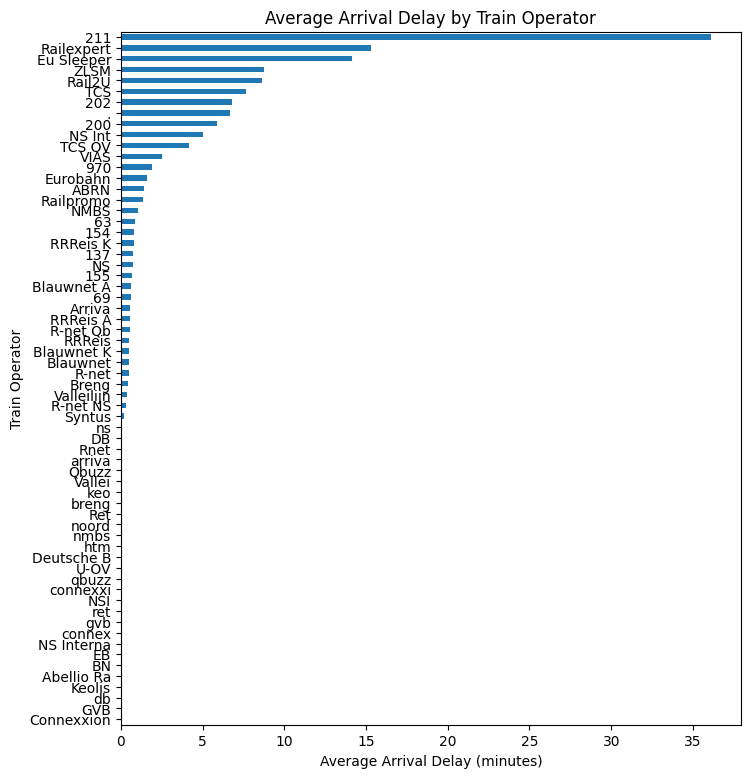

In [12]:
arrival_delay_by_operator = db.sql("""
FROM services
SELECT "Service:Company", AVG("Stop:Arrival delay") AS avg_arrival_delay
GROUP BY ALL
ORDER BY avg_arrival_delay DESC
""").df()

ax = arrival_delay_by_operator.plot.barh(
    x="Service:Company",
    y="avg_arrival_delay",
    title="Average Arrival Delay by Train Operator",
    xlabel="Average Arrival Delay (minutes)",
    ylabel="Train Operator",
    figsize=(8, 9),
    legend=False,
)
ax.invert_yaxis()  # largest delay at the top

### 7.8 How many services were disrupted in different years? Make a line plot.

The `disruptions` table has no service ID, so this counts disruptions per year.

<Axes: title={'center': 'Number of Disruptions by Year'}, xlabel='Year', ylabel='Number of Disruptions'>

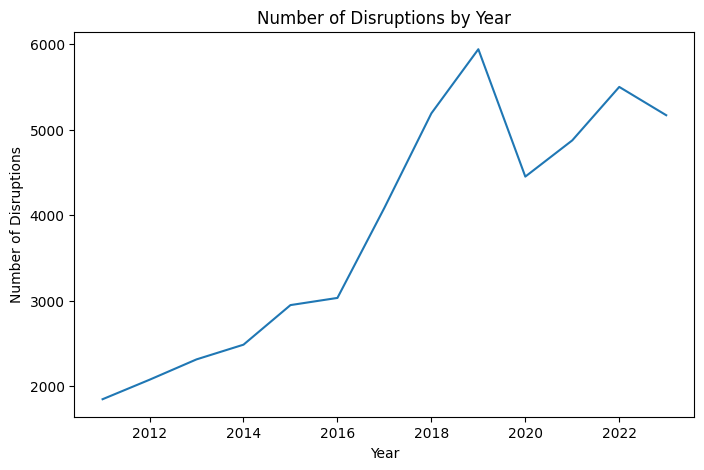

In [13]:
disruptions_by_year = db.sql("""
FROM postgres_db.disruptions
SELECT YEAR(start_time) AS year, COUNT(*) AS num_disruptions
GROUP BY ALL
ORDER BY year
""").df()

disruptions_by_year.plot.line(
    x="year",
    y="num_disruptions",
    title="Number of Disruptions by Year",
    xlabel="Year",
    ylabel="Number of Disruptions",
    figsize=(8, 5),
    legend=False,
)

### 7.9 What fraction of all services were cancelled (`Service:Completely cancelled`) in different years? Make a line plot.

<Axes: title={'center': 'Fraction of Cancelled Services by Year'}, xlabel='Year', ylabel='Fraction of Cancelled Services'>

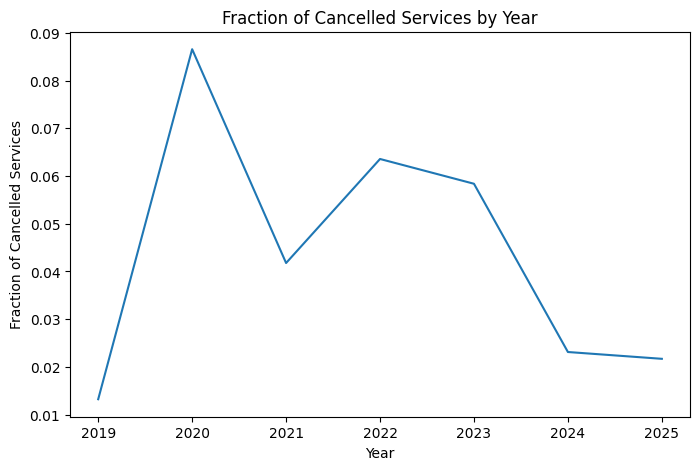

In [14]:
fraction_cancelled_services_by_year = db.sql("""
FROM services
SELECT
    YEAR("Service:Date") AS year,
    COUNT(DISTINCT CASE WHEN "Service:Completely cancelled" THEN "Service:RDT-ID" END) * 1.0
        / COUNT(DISTINCT "Service:RDT-ID") AS fraction_cancelled_services
GROUP BY ALL
ORDER BY year
""").df()

fraction_cancelled_services_by_year.plot.line(
    x="year",
    y="fraction_cancelled_services",
    title="Fraction of Cancelled Services by Year",
    xlabel="Year",
    ylabel="Fraction of Cancelled Services",
    figsize=(8, 5),
    legend=False,
)

## 8. Service lengths

### 8.1 and 8.2 Create table `station_connections`

In [15]:
db.sql("""
CREATE OR REPLACE TABLE station_connections AS
WITH hops AS (
    FROM services
    SELECT
        "Service:RDT-ID",
        "Stop:Station code" AS station,
        LEAD("Stop:Station code") OVER (
            PARTITION BY "Service:RDT-ID"
            ORDER BY "Stop:Departure time"
        ) AS next_station
),
pairs AS (
    FROM hops
    SELECT
        ANY_VALUE("Service:RDT-ID") AS "Service:RDT-ID",
        LEAST(station, next_station) AS start_station_code,
        GREATEST(station, next_station) AS end_station_code
    WHERE next_station IS NOT NULL
    GROUP BY ALL
)
FROM pairs
JOIN distances_long
    ON distances_long.station = pairs.start_station_code
    AND distances_long.other_station = pairs.end_station_code
SELECT "Service:RDT-ID", start_station_code, end_station_code, distance
""")

### 8.3 What is the largest distance between a pair of stations?

In [16]:
db.sql("""
FROM station_connections
SELECT start_station_code, end_station_code, distance
ORDER BY distance DESC
LIMIT 1
""")

┌────────────────────┬──────────────────┬──────────┐
│ start_station_code │ end_station_code │ distance │
│      varchar       │     varchar      │  int64   │
├────────────────────┼──────────────────┼──────────┤
│ STV                │ VS               │      421 │
└────────────────────┴──────────────────┴──────────┘

### 8.4 Plot a histogram of inter-station distances run by trains.

<Axes: title={'center': 'Inter-Station Distances Run by Trains'}, xlabel='Distance (km)', ylabel='Number of Station Pairs'>

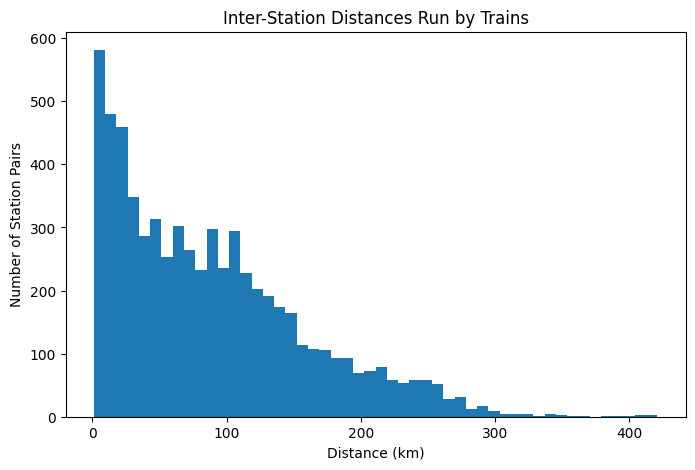

In [17]:
connection_distances = db.sql("""
FROM station_connections
SELECT distance
""").df()

connection_distances.plot.hist(
    bins=50,
    title="Inter-Station Distances Run by Trains",
    xlabel="Distance (km)",
    ylabel="Number of Station Pairs",
    figsize=(8, 5),
    legend=False,
)